# Proving the ideas: filters, bullish divergences, 4-hour bars and combined signals

The last notebook found that **shorting after a daily MACD or RSI bearish divergence** looked good, but the patterns had been picked using the same 2024+ data they were tested on.
This notebook puts every idea from the "what to try next" list through one **strict protocol** that was fixed before looking at any results.

**Ideas tested**
1. **Trend and volume filters**: only trade when price is above/below its 50- or 200-day average, or when volume is unusually high or low.
2. **Bullish divergences** (longs), both regular and hidden, with the same filters.
3. **4-hour bars** instead of daily (resampled from the hourly data).
4. **Combined signals**: MACD and RSI divergence together (within 3 bars), and divergence plus a double top (within 10 bars).
5. The earlier winners (double bottom, three white soldiers, rectangle breakout) **re-tested with filters**.

**Protocol**
- A strategy = pattern + entry filter + exit rules (stop / target / maximum hold). Entry is at the next bar's open; costs are 0.15% per side (0.30% round trip); stop is assumed to hit first if a bar touches both.
- The **filter and exit rules are chosen using only trades entered before 2024**, then run unchanged on 2024 onward.
- Each strategy is compared with **random entries that obey the same filter, direction and exit rules**, so a filter or a market trend cannot create an edge by itself.
- About 38 strategies are tried, so p-values are corrected for that (Benjamini-Hochberg *q-value*).
- Every pattern is tested twice: **unfiltered** (exit rules tuned only) and with the **best filter** (picked on the earlier period).
- **A strategy is "proven" only if ALL of these hold:** ≥30 trades since 2024, q-value < 0.10, positive average net return from 2025 on, and a positive average on at least 4 of the 6 coins.
- Coins: ETH, SOL, BNB, XRP, ADA, DOGE. Proven strategies get one more test: rules tuned on three coins are traded on the other three.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from strategy_lab import (COINS, prepare, prepare_4h, add_features, add_confluence, FILTERS, GRID_DAILY, GRID_4H,
                          evaluate, judge, cross_validate)
from trade_sim import trade_stats

TEST_START = '2024-01-01'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c98500', '#d55181', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.8, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 40)

daily = prepare(COINS, 'daily', TEST_START)
add_features(daily)
four_h = prepare_4h(COINS, TEST_START)
add_features(four_h, tf_secs=14400)

for cd, w in ((daily, 3), (four_h, 3)):
    add_confluence(cd, 'macd_and_rsi_bear', 'macd_bear_div', 'rsi_bear_div', -1, w)
    add_confluence(cd, 'macd_and_rsi_bull', 'macd_bull_div', 'rsi_bull_div', 1, w)
add_confluence(daily, 'bear_div_and_double_top', 'macd_bear_div', 'double_top', -1, 10)

print('daily bars per coin:', {s[:-4]: len(c['ohlc']) for s, c in daily.items()})
print('4h bars per coin:   ', {s[:-4]: len(c['ohlc']) for s, c in four_h.items()})

daily bars per coin: {'ETH': 3208, 'SOL': 2255, 'BNB': 3208, 'XRP': 3085, 'ADA': 3102, 'DOGE': 2658}
4h bars per coin:    {'ETH': 19237, 'SOL': 13534, 'BNB': 19237, 'XRP': 18504, 'ADA': 18607, 'DOGE': 15948}


In [2]:
DAILY = [('macd_bear_div', -1), ('rsi_bear_div', -1), ('rsi_hidden_bear_div', -1), ('macd_hidden_bear_div', -1),
         ('macd_and_rsi_bear', -1), ('bear_div_and_double_top', -1),
         ('rsi_bull_div', 1), ('macd_bull_div', 1), ('rsi_hidden_bull_div', 1), ('macd_hidden_bull_div', 1),
         ('macd_and_rsi_bull', 1), ('double_bottom', 1), ('three_white_soldiers', 1), ('rectangle_up', 1)]
FOUR_H = [('macd_bear_div', -1), ('rsi_bear_div', -1), ('macd_and_rsi_bear', -1),
          ('rsi_bull_div', 1), ('macd_bull_div', 1), ('macd_and_rsi_bull', 1)]
NO_VOL = tuple(f for f in FILTERS if not f.startswith('vol'))   # 4h data has no volume series here

rows, recs = [], {}
def run_family(coins, cands, grid, filter_sets, tf):
    for pat, d in cands:
        for mode, fs in filter_sets.items():
            out = evaluate(coins, pat, d, TEST_START, grid, filters=fs)
            if out is None:
                continue
            row, rec = out
            row.update(tf=tf, mode=mode)
            rows.append(row); recs[(tf, pat, mode)] = rec

run_family(daily, DAILY, GRID_DAILY, {'unfiltered': ('none',), 'best filter': tuple(FILTERS)}, 'daily')
run_family(four_h, FOUR_H, GRID_4H, {'unfiltered': ('none',), 'best filter': NO_VOL}, '4h')

results = judge(pd.DataFrame(rows))
print(len(results), 'strategies evaluated;', int(results['proven'].sum()), 'proven')

40 strategies evaluated; 2 proven


## 1. Results for every strategy (2024 onward)

`is_avg_net_pct` is the average per trade on the earlier period that was used to pick the filter and rules. `avg_net_pct` is what happened afterwards.
`random_avg_pct` is the average for random entries using the same filter, direction and exit rules. `coins_pos` = coins with a positive average.

In [3]:
cols = ['tf', 'pattern', 'side', 'mode', 'filter', 'rules', 'is_avg_net_pct', 'n', 'win_rate', 'avg_net_pct', 'random_avg_pct',
        'profit_factor', 'p_value', 'q_value', 'avg_net_2025_pct', 'n_2025', 'coins_pos', 'proven']
table = results.sort_values(['proven', 'q_value'], ascending=[False, True])[cols].reset_index(drop=True)
table.round(2)

,tf,pattern,side,mode,filter,rules,is_avg_net_pct,n,win_rate,avg_net_pct,random_avg_pct,profit_factor,p_value,q_value,avg_net_2025_pct,n_2025,coins_pos,proven
0,daily,macd_bear_div,short,unfiltered,none,stop 1.0 / tgt 2.0 / 20 bars,1.07,64,0.56,3.96,0.34,2.63,0.00,0.07,2.34,41,5,True
1,daily,macd_and_rsi_bear,short,unfiltered,none,stop 2.0 / tgt 2.0 / 10 bars,1.24,33,0.67,5.12,0.37,3.52,0.00,0.07,2.50,19,6,True
2,daily,macd_and_rsi_bear,short,best filter,vol_quiet,stop 2.0 / tgt 2.0 / 10 bars,2.72,18,0.67,5.12,0.41,3.73,0.01,0.13,3.21,11,5,False
3,daily,rsi_bear_div,short,unfiltered,none,stop 2.0 / tgt 2.0 / 10 bars,1.51,44,0.61,3.60,0.41,2.18,0.02,0.13,2.26,25,4,False
4,daily,double_bottom,long,unfiltered,none,stop 2.0 / tgt - / 10 bars,2.40,47,0.51,3.69,-0.64,1.91,0.01,0.13,0.64,31,3,False
5,daily,rsi_bear_div,short,best filter,vol_quiet,stop 2.0 / tgt 2.0 / 10 bars,4.68,23,0.65,4.49,0.43,2.75,0.03,0.17,2.74,14,5,False
6,daily,rectangle_up,long,unfiltered,none,stop - / tgt - / 10 bars,4.18,34,0.50,4.19,-0.14,2.13,0.03,0.17,-2.82,20,4,False
7,4h,macd_bear_div,short,best filter,with_sma200,stop - / tgt 2.0 / 60 bars,1.56,106,0.72,1.35,-0.01,1.77,0.03,0.17,2.28,73,4,False
8,daily,macd_bear_div,short,best filter,with_sma200,stop - / tgt 3.0 / 20 bars,2.86,18,0.67,3.63,-0.96,2.16,0.09,0.31,3.43,15,4,False
9,daily,three_white_soldiers,long,unfiltered,none,stop - / tgt - / 20 bars,13.54,43,0.42,3.82,-0.01,1.61,0.09,0.31,-1.45,24,5,False


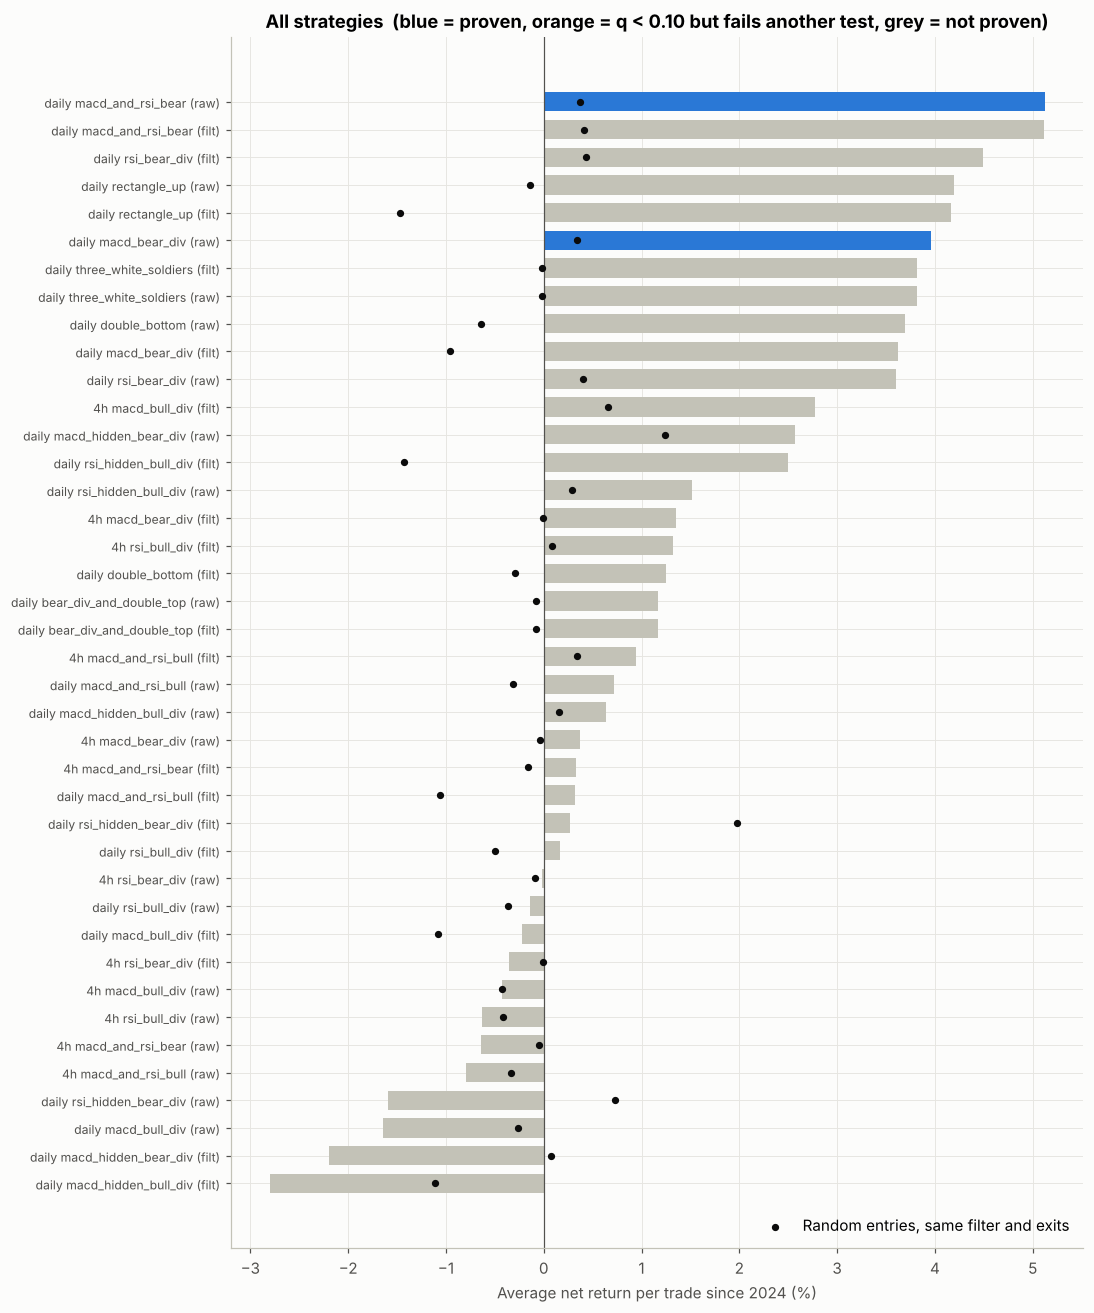

In [4]:
t = results.sort_values('avg_net_pct').reset_index(drop=True)
labels = [f"{r.tf} {r.pattern} ({'filt' if r['mode'] == 'best filter' else 'raw'})" for _, r in t.iterrows()]
colors = [BLUE if p else (ORANGE if q < 0.1 else '#c3c2b7') for p, q in zip(t['proven'], t['q_value'])]
fig, ax = plt.subplots(figsize=(10, 0.32 * len(t) + 1.5))
y = np.arange(len(t))
ax.barh(y, t['avg_net_pct'], color=colors, height=0.7)
ax.scatter(t['random_avg_pct'], y, color='#0b0b0b', s=14, zorder=3, label='Random entries, same filter and exits')
ax.axvline(0, color='#52514e', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel('Average net return per trade since 2024 (%)')
ax.set_title('All strategies  (blue = proven, orange = q < 0.10 but fails another test, grey = not proven)')
ax.legend(frameon=False, loc='lower right')
plt.show()

## 2. Did the filters help?

For each pattern: the unfiltered strategy vs. the one with the filter chosen on the earlier period.

In [5]:
pv = results.pivot_table(index=['tf', 'pattern'], columns='mode', values=['avg_net_pct', 'n', 'p_value'])
cmp_tbl = pd.DataFrame({
    'unfiltered avg %': pv[('avg_net_pct', 'unfiltered')], 'unfiltered n': pv[('n', 'unfiltered')],
    'best-filter avg %': pv[('avg_net_pct', 'best filter')], 'best-filter n': pv[('n', 'best filter')],
})
cmp_tbl['filter chosen'] = results[results['mode'] == 'best filter'].set_index(['tf', 'pattern'])['filter']
cmp_tbl['filter helped?'] = np.where(cmp_tbl['best-filter avg %'] > cmp_tbl['unfiltered avg %'], 'yes', 'no')
print('Filter helped in', int((cmp_tbl['filter helped?'] == 'yes').sum()), 'of', len(cmp_tbl), 'patterns')
cmp_tbl.round(2)

Filter helped in 10 of 20 patterns


unfiltered avg %  unfiltered n  best-filter avg %  best-filter n   filter chosen filter helped?
tf    pattern                                                                                                                 
4h    macd_and_rsi_bear                   -0.64         145.0               0.33           33.0     with_sma200            yes
      macd_and_rsi_bull                   -0.80         186.0               0.94           31.0     with_sma200            yes
      macd_bear_div                        0.37         317.0               1.35          106.0     with_sma200            yes
      macd_bull_div                       -0.43         413.0               2.77           94.0     with_sma200            yes
      rsi_bear_div                        -0.02         178.0              -0.35           38.0     with_sma200             no
      rsi_bull_div                        -0.64         237.0               1.33           18.0      with_sma50            yes
daily bear_div_and_double_top              1.17          14.0               1.17           14.0            none             no
      double_bottom                        3.69          47.0               1.25           27.0  against_sma200             no
      macd_and_rsi_bear                    5.12          33.0               5.12           18.0       vol_quiet             no
      macd_and_rsi_bull                    0.72          38.0               0.32           31.0       vol_quiet             no
      macd_bear_div                        3.96          64.0               3.63           18.0     with_sma200             no
      macd_bull_div                       -1.64          75.0              -0.22           53.0       vol_quiet            yes
      macd_hidden_bear_div                 2.57          67.0              -2.19           43.0     with_sma200             no
      macd_hidden_bull_div                 0.64          66.0              -2.80           17.0   against_sma50             no
      rectangle_up                         4.19          34.0               4.16           19.0     with_sma200             no
      rsi_bear_div                         3.60          44.0               4.49           23.0       vol_quiet            yes
      rsi_bull_div                        -0.14          47.0               0.16           31.0  against_sma200            yes
      rsi_hidden_bear_div                 -1.59          42.0               0.27           21.0       vol_quiet            yes
      rsi_hidden_bull_div                  1.52          34.0               2.49           26.0     with_sma200            yes
      three_white_soldiers                 3.82          43.0               3.82           43.0            none             no

## 3. Bullish divergences and 4-hour bars

In [6]:
bull = results[results['pattern'].str.contains('bull') | (results['pattern'].isin(['double_bottom', 'three_white_soldiers', 'rectangle_up']))]
print('LONG strategies, daily and 4h: best average net per trade since 2024, and 2025 onward')
bull[['tf', 'pattern', 'mode', 'filter', 'n', 'avg_net_pct', 'random_avg_pct', 'q_value', 'avg_net_2025_pct', 'coins_pos']].sort_values('avg_net_2025_pct', ascending=False).round(2)

LONG strategies, daily and 4h: best average net per trade since 2024, and 2025 onward


,tf,pattern,mode,filter,n,avg_net_pct,random_avg_pct,q_value,avg_net_2025_pct,coins_pos
37,4h,macd_bull_div,best filter,with_sma200,94,2.77,0.66,0.31,1.49,4
23,daily,double_bottom,best filter,against_sma200,27,1.25,-0.30,0.52,1.22,4
22,daily,double_bottom,unfiltered,none,47,3.69,-0.64,0.13,0.64,3
18,daily,macd_hidden_bull_div,unfiltered,none,66,0.64,0.16,0.58,0.40,4
17,daily,rsi_hidden_bull_div,best filter,with_sma200,26,2.49,-1.42,0.38,0.24,4
13,daily,rsi_bull_div,best filter,against_sma200,31,0.16,-0.50,0.58,-0.24,4
36,4h,macd_bull_div,unfiltered,none,413,-0.43,-0.42,0.67,-0.55,0
20,daily,macd_and_rsi_bull,unfiltered,none,38,0.72,-0.31,0.55,-0.61,2
34,4h,rsi_bull_div,unfiltered,none,237,-0.64,-0.42,0.90,-0.67,0
19,daily,macd_hidden_bull_div,best filter,against_sma50,17,-2.80,-1.12,0.77,-0.97,4


In [7]:
h4 = results[results['tf'] == '4h']
print('4-HOUR strategies')
h4[['pattern', 'side', 'mode', 'filter', 'n', 'win_rate', 'avg_net_pct', 'random_avg_pct', 'q_value', 'avg_net_2025_pct', 'coins_pos']].sort_values('q_value').round(2)

4-HOUR strategies


,pattern,side,mode,filter,n,win_rate,avg_net_pct,random_avg_pct,q_value,avg_net_2025_pct,coins_pos
29,macd_bear_div,short,best filter,with_sma200,106,0.72,1.35,-0.01,0.17,2.28,4
28,macd_bear_div,short,unfiltered,none,317,0.43,0.37,-0.04,0.31,0.61,4
37,macd_bull_div,long,best filter,with_sma200,94,0.54,2.77,0.66,0.31,1.49,4
35,rsi_bull_div,long,best filter,with_sma50,18,0.56,1.33,0.09,0.55,-1.59,4
33,macd_and_rsi_bear,short,best filter,with_sma200,33,0.30,0.33,-0.16,0.56,1.80,3
30,rsi_bear_div,short,unfiltered,none,178,0.40,-0.02,-0.09,0.58,0.36,2
39,macd_and_rsi_bull,long,best filter,with_sma200,31,0.52,0.94,0.34,0.58,-2.17,3
36,macd_bull_div,long,unfiltered,none,413,0.35,-0.43,-0.42,0.67,-0.55,0
31,rsi_bear_div,short,best filter,with_sma200,38,0.26,-0.35,-0.01,0.76,1.02,2
38,macd_and_rsi_bull,long,unfiltered,none,186,0.13,-0.80,-0.33,0.89,-1.21,0


## 4. Deeper checks on the best strategies

Cumulative return, results by year and by coin, and the **cross-coin test**: filter and exit rules are chosen on three coins before 2024, then traded on the *other three* coins from 2024.
Shown for the strategies with the lowest q-values (up to 4).

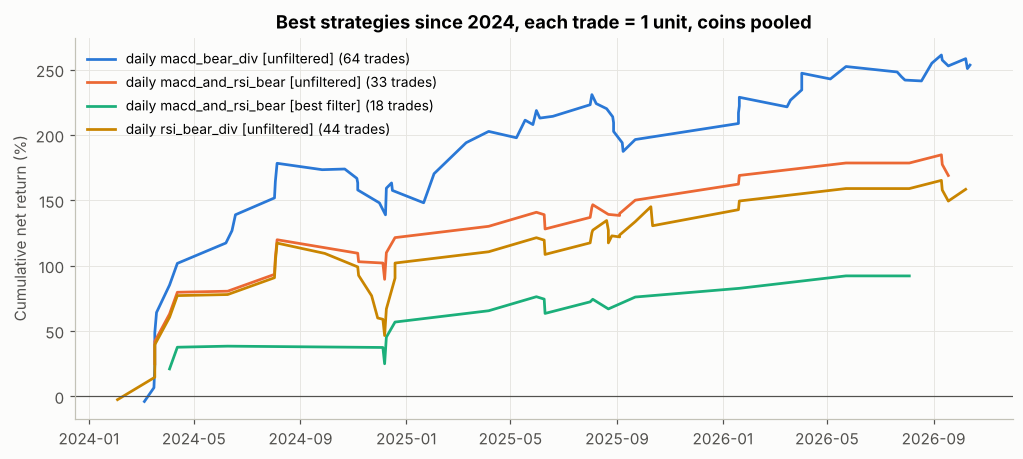

Average net % per trade by entry year


entry,2024,2025,2026
daily macd_bear_div [unfiltered],6.85,1.95,2.71
daily macd_and_rsi_bear [unfiltered],8.68,2.39,2.70
daily macd_and_rsi_bear [best filter],8.12,2.39,5.39
daily rsi_bear_div [unfiltered],5.37,1.68,3.48


Average net % per trade by coin


,ADA,BNB,DOGE,ETH,SOL,XRP
daily macd_bear_div [unfiltered],12.13,1.61,2.19,-0.09,4.77,7.18
daily macd_and_rsi_bear [unfiltered],15.58,0.87,10.74,0.29,4.72,8.90
daily macd_and_rsi_bear [best filter],20.36,-0.20,6.01,2.82,8.24,6.36
daily rsi_bear_div [unfiltered],9.69,-1.22,11.99,-0.71,5.33,1.52


In [8]:
top = results.sort_values('q_value').head(4)
keys = [(r.tf, r.pattern, r['mode']) for _, r in top.iterrows()]
palette = [BLUE, ORANGE, AQUA, YELLOW]
fig, ax = plt.subplots()
for k, c in zip(keys, palette):
    t = recs[k].sort_values('exit')
    ax.plot(t['exit'], 100 * t['net'].cumsum(), color=c, label=f"{k[0]} {k[1]} [{k[2]}] ({len(t)} trades)")
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_ylabel('Cumulative net return (%)'); ax.set_title('Best strategies since 2024, each trade = 1 unit, coins pooled')
ax.legend(frameon=False, loc='upper left', fontsize=9)
plt.show()

yr = pd.DataFrame({f'{k[0]} {k[1]} [{k[2]}]': 100 * recs[k].groupby(recs[k]['entry'].dt.year)['net'].mean() for k in keys}).round(2)
print('Average net % per trade by entry year'); display(yr.T)
co = pd.DataFrame({f'{k[0]} {k[1]} [{k[2]}]': 100 * recs[k].groupby('coin')['net'].mean() for k in keys}).round(2)
co.index = [c[:-4] for c in co.index]
print('Average net % per trade by coin'); display(co.T)

In [9]:
A = ['ETHUSDT', 'BNBUSDT', 'ADAUSDT']; B = ['SOLUSDT', 'XRPUSDT', 'DOGEUSDT']
rows = []
for _, r in top.iterrows():
    coins = daily if r['tf'] == 'daily' else four_h
    grid = GRID_DAILY if r['tf'] == 'daily' else GRID_4H
    fs = ('none',) if r['mode'] == 'unfiltered' else (tuple(FILTERS) if r['tf'] == 'daily' else NO_VOL)
    d = 1 if r['side'] == 'long' else -1
    for tr_c, te_c in ((A, B), (B, A)):
        out = cross_validate(coins, r['pattern'], d, tr_c, te_c, TEST_START, grid, fs)
        if out:
            rows.append(dict(strategy=f"{r['tf']} {r['pattern']} [{r['mode']}]", **out))
pd.DataFrame(rows).round(2)

,strategy,train,test,filter,n,win_rate,avg_net_pct,random_avg_pct,p_value
0,daily macd_bear_div [unfiltered],"ETH,BNB,ADA","SOL,XRP,DOGE",none,28,0.57,4.45,0.39,0.02
1,daily macd_bear_div [unfiltered],"SOL,XRP,DOGE","ETH,BNB,ADA",none,33,0.67,4.49,0.61,0.02
2,daily macd_and_rsi_bear [unfiltered],"ETH,BNB,ADA","SOL,XRP,DOGE",none,14,0.64,6.05,0.33,0.03
3,daily macd_and_rsi_bear [best filter],"ETH,BNB,ADA","SOL,XRP,DOGE",vol_quiet,8,0.75,5.03,0.33,0.06
4,daily rsi_bear_div [unfiltered],"ETH,BNB,ADA","SOL,XRP,DOGE",none,20,0.60,3.28,0.01,0.02
5,daily rsi_bear_div [unfiltered],"SOL,XRP,DOGE","ETH,BNB,ADA",none,25,0.52,1.20,0.65,0.38


## Conclusions

**Outcome: 40 strategies tested, 2 passed every test, and they are really one idea.** Both are **shorting after a daily MACD bearish divergence**; the second version also requires an RSI divergence within 3 bars, so most of its signals are the same trades.

| Strategy (daily, short) | Trades since 2024 | Avg net / trade | Random entries | q-value | From 2025 on | Coins positive |
|---|---|---|---|---|---|---|
| MACD bearish divergence | 64 | **+3.96%** | +0.34% | 0.07 | +2.34% (41 trades) | 5 of 6 |
| MACD **and** RSI bearish divergence | 33 | **+5.12%** | +0.37% | 0.07 | +2.50% (19 trades) | 6 of 6 |

Cross-coin check: MACD-divergence rules tuned on ETH/BNB/ADA made **+4.5%** per trade on SOL/XRP/DOGE (p = 0.02), and tuned the other way round they made **+4.5%** on ETH/BNB/ADA (p = 0.02).

**What happened to each idea**
1. **Trend and volume filters helped in only 10 of 20 patterns, and not for the best strategies.** For daily MACD divergence the filter cut trades from 64 to 18 and did not improve the result (+3.6% vs +4.0%). Where it did matter was 4-hour bars: a 200-bar trend filter turned 4-hour MACD divergence shorts from +0.4% to **+1.35%** per trade (106 trades, 72% win rate, +2.3% since 2025), but q = 0.17, so it is **not proven**.
2. **Bullish divergences (longs): nothing works.** Best case was 4-hour MACD bullish divergence with a trend filter (+2.8%, q = 0.31). Every daily bullish divergence is flat or negative since 2025.
3. **4-hour bars: none proven.** Unfiltered 4-hour signals are mostly at or below zero after costs.
4. **Combined signals:** MACD + RSI together is the stronger version above. Divergence + double top produced only 14 trades, too few to judge.
5. **Earlier winners fail the stricter test.** Double bottom (q = 0.13, only 3 of 6 coins), rectangle breakout (q = 0.17, −2.8% since 2025) and three white soldiers (q = 0.31, −1.5% since 2025) were all 2024 effects. RSI bearish divergence alone narrowly missed (q = 0.13; its cross-coin check passed one way and failed the other).

**What "proven" means here, and what it does not**
- It means the strategy passed tests that were fixed *before* seeing the results: tuned only on pre-2024 trades, beat filter-matched random entries after costs, still profitable from 2025, positive on most coins.
- It does **not** mean it will make money from here. Returns per trade have shrunk from **+6.9% in 2024 to about +2–2.7% in 2025–2026.**
- The q-values are optimistic: 40 is only the number tested *in this notebook*; many more patterns and variants were examined earlier on the same data.
- Signals on different coins arrive together, so 64 trades are fewer independent bets than they look. Shorts ignore funding costs.
- Last two months (Aug 15 – Oct 13, 2026), the three configured strategies made 13 trades with an average net of −0.05%: flat, on a small sample.

**Next step: forward test.** `paper_trade.py` logs what these rules would do on new daily candles, starting 2026-10-14 with the rules frozen in `paper_strategies.json`. New data is the only test that can't be tainted by hindsight.